### DMW: Differentialgleichungen, Richtungsfelder und Euler-Verfahren - Übungen

Dieses Notebook gehört zum Wahlfach **Digitale Mathematische Werkzeuge**. Viele Vorgänge beschreibt man am einfachsten über ihre
**Änderungsrate**: Eine Population wächst umso schneller, je größer sie ist; eine Feder zieht umso stärker zurück, je weiter sie ausgelenkt ist.
Solche Gesetze sind **Differentialgleichungen**: Gleichungen, in denen eine unbekannte Funktion und ihre Ableitungen vorkommen.

Du siehst Lösungen im **Richtungsfeld**, prüfst, ob eine Funktion eine Lösung ist, untersuchst logistisches Wachstum und Schwingungen
und berechnest Näherungslösungen mit dem **Euler-Verfahren**, so wie es Computer tun, wenn es keine Formel für die Lösung gibt.

Vorausgesetzt werden die Notebooks *Wachstum* (`dsolve`, `checkodesol`) und *Integrale*.

Jeder Abschnitt beginnt mit kurzen Erklärungen und Beispielen. Führe die Beispiele aus und probiere sie ruhig ein wenig aus.
Danach folgen viele kleine Übungen. Unter den meisten Aufgaben steht das **erwartete Ergebnis**.

**Brüche und Kommazahlen:** Python rechnet `1/6` oder `0.5` sofort als Kommazahl, bevor sympy die Zahl sieht.
Die erwarteten Ausgaben sind aber mit exakten Brüchen berechnet. Schreibe solche Zahlen deshalb mit `Rational`: `Rational(1, 6)` für 1/6,
`Rational('0.5')` für 0,5. Bei einer Division ganzer Zahlen genügt es, eine davon mit `Integer` zu schreiben: `Integer(1) / 6`.
Aufgaben, bei denen das nötig ist, haben einen entsprechenden Hinweis.

Unter den Aufgaben kannst du jeweils die Lösung aufklappen. Versuche es aber immer zuerst selbst!
Bei den Aufgaben „Was wird ausgegeben?“ gibt es keine Lösung zum Aufklappen: Dort führst du einfach die Zelle aus und vergleichst.

#### sympy laden

**Führe diese Zelle zuerst aus** (und nach jedem Neustart des Kernels wieder). Sie lädt sympy und matplotlib, schaltet die Formel-Ausgabe ein und legt an:
- die reellen Variablen `x`, `y`, die positiven Parameter `k`, `n`, `G` und die Konstanten `C1`, `C2`,
- `Y`: die gesuchte Funktion y(x) für `dsolve` und `checkodesol`,
- `dgl(steigung)`: macht aus einem Steigungsterm in x und y die Differentialgleichung y' = steigung, z. B. `dgl(x * y)` für y' = x·y,
- `richtungsfeld(steigung, xb, yb, schritt)`: zeichnet das Richtungsfeld von y' = steigung im Bereich xb × yb (danach `plt.show()`).

In [ ]:
from sympy import *
init_printing()
import matplotlib.pyplot as plt
x, y = symbols('x y', real=True)
k, n, G = symbols('k n G', positive=True)
C1, C2 = symbols('C1 C2')
Y = Function('y')

def dgl(steigung):
    """Die Differentialgleichung y' = steigung für dsolve und checkodesol."""
    return Eq(Y(x).diff(x), steigung.subs(y, Y(x)))

def richtungsfeld(steigung, xb=(-3, 3), yb=(-3, 3), schritt=0.5):
    """Zeichnet das Richtungsfeld von y' = steigung (Term in x und y) als gleich lange Striche."""
    f = lambdify((x, y), steigung, 'math')
    xs, ys, us, vs = [], [], [], []
    for i in range(round((xb[1] - xb[0]) / schritt) + 1):
        for j in range(round((yb[1] - yb[0]) / schritt) + 1):
            a, b = xb[0] + i * schritt, yb[0] + j * schritt
            try:
                m = f(a, b)
            except (ZeroDivisionError, ValueError):
                continue
            xs.append(a)
            ys.append(b)
            us.append(1 / (1 + m**2)**0.5)
            vs.append(m / (1 + m**2)**0.5)
    plt.quiver(xs, ys, us, vs, angles='xy', pivot='mid', headwidth=1, headlength=0, headaxislength=0)
    plt.xlim(xb)
    plt.ylim(yb)

## 1. Richtungsfelder

#### Die Steigung in jedem Punkt

Eine Differentialgleichung y' = f(x, y) sagt in jedem Punkt (x | y), welche **Steigung** eine Lösungskurve dort hat. Zeichnet man an vielen Punkten kleine
Striche mit dieser Steigung, erhält man das **Richtungsfeld**. Lösungskurven verlaufen überall in Richtung der Striche; durch jeden Punkt geht genau eine.

Man sieht oft schon am Richtungsfeld, wie sich Lösungen verhalten (wachsen, fallen, sich einer Geraden nähern), ohne eine Formel zu kennen.

In [ ]:
richtungsfeld(x - y)
loes = dsolve(dgl(x - y), Y(x), ics={Y(0): 1})
display(loes)
fl = lambdify(x, loes.rhs)
xs = [-3 + i / 20 for i in range(121)]
plt.plot(xs, [fl(w) for w in xs], 'r')
plt.show()

#### Aufgabe 1.1

Zeichne das Richtungsfeld von y' = y für −3 ≤ x, y ≤ 3.

**Erwartete Ausgabe:**



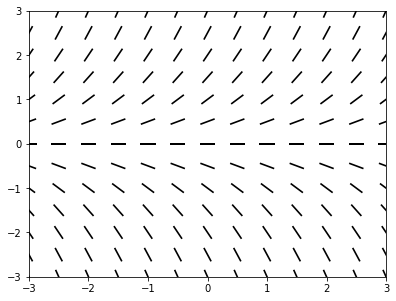

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
richtungsfeld(y)
plt.show()
```

</details>

#### Aufgabe 1.2

Zeichne das Richtungsfeld von y' = −x/y (die Punkte mit y = 0 lässt die Funktion weg). Die Lösungen sind Kreise.

**Erwartete Ausgabe:**



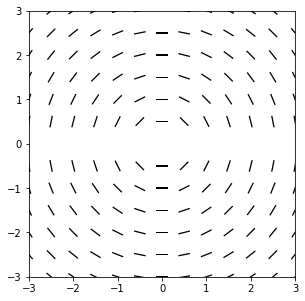

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
richtungsfeld(-x / y)
plt.gca().set_aspect('equal')
plt.show()
```

</details>

#### Aufgabe 1.3

Zeichne das Richtungsfeld von y' = y/x für −3 ≤ x, y ≤ 3 mit der Schrittweite 0,4.

**Erwartete Ausgabe:**



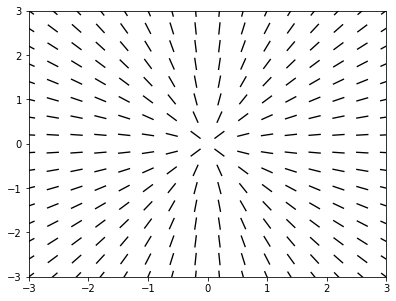

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
richtungsfeld(y / x, schritt=0.4)
plt.show()
```

</details>

#### Aufgabe 1.4

Zeichne das Richtungsfeld von y' = x² − y für −2 ≤ x ≤ 3, −1 ≤ y ≤ 5 und dazu die Lösung durch (0 | 0) (mit `dsolve` und `lambdify` wie im Beispiel).

**Erwartete Ausgabe:**



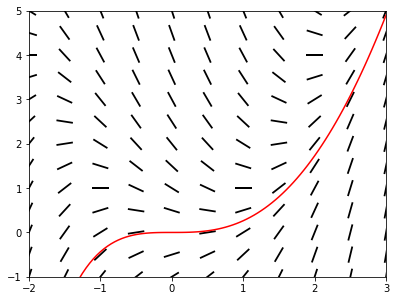

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
richtungsfeld(x**2 - y, xb=(-2, 3), yb=(-1, 5))
loes = dsolve(dgl(x**2 - y), Y(x), ics={Y(0): 0})
fl = lambdify(x, loes.rhs)
xs = [-2 + i / 20 for i in range(101)]
plt.plot(xs, [fl(w) for w in xs], 'r')
plt.show()
```

</details>

#### Aufgabe 1.5

An welchen Punkten hat jede Lösung von y' = x − y eine waagrechte Tangente? Löse x − y = 0 nach y auf (das ist die **Isokline** zur Steigung 0).

**Erwartete Ausgabe:**

$\displaystyle \left[ x\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
solve(Eq(x - y, 0), y)
```

</details>

## 2. Lösungen prüfen

#### Einsetzen und vergleichen

Ob eine Funktion y = g(x) Lösung von y' = f(x, y) ist, prüft man durch Einsetzen: g'(x) − f(x, g(x)) muss für alle x null sein.
`checkodesol(dgl(...), Eq(Y(x), g))` macht das und gibt `(True, 0)` bei einer Lösung aus.

Eine Lösung mit einer Konstanten C1 heißt **allgemeine Lösung**; jedes C1 gibt eine Kurve im Richtungsfeld.

In [ ]:
g = C1 * x
display(simplify(diff(g, x) - (y / x).subs(y, g)))
display(checkodesol(dgl(y / x), Eq(Y(x), g)))
checkodesol(dgl(y / x), Eq(Y(x), x**2))

#### Aufgabe 2.1

Prüfe von Hand (Ableitung minus rechte Seite, vereinfacht), ob y = C1 · e^(kx) die Gleichung y' = k·y löst.

**Erwartete Ausgabe:**

$\displaystyle 0$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
g = C1 * exp(k*x)
simplify(diff(g, x) - k * g)
```

</details>

#### Aufgabe 2.2

Prüfe mit `checkodesol`, ob y = C1 · x² die Gleichung y' = 2y/x löst.

**Erwartete Ausgabe:**

```
(True, 0)
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
checkodesol(dgl(2*y / x), Eq(Y(x), C1 * x**2))
```

</details>

#### Aufgabe 2.3

Prüfe mit `checkodesol`, ob y = C1 · xⁿ die Gleichung y' = n·y/x löst.

**Erwartete Ausgabe:**

```
(True, 0)
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
checkodesol(dgl(n*y / x), Eq(Y(x), C1 * x**n))
```

</details>

#### Aufgabe 2.4

Prüfe, ob y = C1·x/(1 − C1·x) die Gleichung y' = (y + y²)/x löst (mit `checkodesol`), und ob y = x/(1 − x) eine spezielle Lösung ist.

**Erwartete Ausgabe:**

```
(True, 0)
```

```
(True, 0)
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(checkodesol(dgl((y + y**2) / x), Eq(Y(x), C1 * x / (1 - C1 * x))))
checkodesol(dgl((y + y**2) / x), Eq(Y(x), x / (1 - x)))
```

</details>

#### Aufgabe 2.5

Welche der Funktionen x³, 2x³, x² + 1 und 3x lösen y' = 3y/x? (Liste der Wahrheitswerte: erstes Element von `checkodesol`)

**Erwartete Ausgabe:**

```
[True, True, False, False]
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
[checkodesol(dgl(3*y / x), Eq(Y(x), g))[0] for g in [x**3, 2*x**3, x**2 + 1, 3*x]]
```

</details>

#### Aufgabe 2.6

Bestimme C1 so, dass die Lösung y = C1 · x² von y' = 2y/x durch den Punkt (2 | 6) geht.

**Erwartete Ausgabe:**

$\displaystyle \left[ \frac{3}{2}\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
solve(Eq(C1 * 2**2, 6), C1)
```

</details>

#### Aufgabe 2.7

Löse y' = y/x und y' = n·y/x mit `dsolve` allgemein.

**Erwartete Ausgabe:**

$\displaystyle y{\left(x \right)} = C_{1} x$

$\displaystyle y{\left(x \right)} = C_{1} x^{n}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(dsolve(dgl(y / x), Y(x)))
dsolve(dgl(n*y / x), Y(x))
```

</details>

#### Aufgabe 2.8

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
display(checkodesol(dgl(y), Eq(Y(x), exp(x))))
display(checkodesol(dgl(y), Eq(Y(x), 5 * exp(x))))
checkodesol(dgl(y), Eq(Y(x), exp(x) + 1))[0]
```

In [ ]:
display(checkodesol(dgl(y), Eq(Y(x), exp(x))))
display(checkodesol(dgl(y), Eq(Y(x), 5 * exp(x))))
checkodesol(dgl(y), Eq(Y(x), exp(x) + 1))[0]

## 3. Logistisches Wachstum

#### y' = k · y · (G − y)

Beim **logistischen Wachstum** ist die Wachstumsrate proportional zum Bestand y **und** zum Abstand zur Grenze G. Am Anfang wächst der Bestand fast
exponentiell, später bremst er ab und nähert sich G. Lösungen sind

y(x) = G / (1 + a·e^(−k·G·x))  mit a = G/y(0) − 1.

Ohne die Lösung zu kennen, liest man aus der DGL ab: Für 0 < y < G ist y' > 0; y' ist am größten bei y = G/2 (dort ist der **Wendepunkt**).

In [ ]:
steig = k * y * (G - y)
display(solve(diff(steig, y), y))
loes = G / (1 + C1 * exp(-k * G * x))
display(checkodesol(dgl(steig), Eq(Y(x), loes)))
f = Rational(1, 50) * y * (10 - y)
richtungsfeld(f, xb=(0, 40), yb=(0, 12), schritt=2)
g = 10 / (1 + 9 * exp(-Rational(1, 5) * x))
xs = list(range(41))
plt.plot(xs, [float(g.subs(x, w)) for w in xs], 'r')
plt.show()

#### Aufgabe 3.1

Für welchen Bestand y ist das Wachstum y' = 0,02·y·(10 − y) am größten, und wie groß ist es dann?

*Schreibe Brüche und Kommazahlen mit `Rational`, z. B. `Rational(1, 6)` oder `Rational('0.5')`.*

**Erwartete Ausgabe:**

$\displaystyle \left( 5, \  \frac{1}{2}\right)$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
steig = Rational(2, 100) * y * (10 - y)
ym = solve(diff(steig, y), y)[0]
(ym, steig.subs(y, ym))
```

</details>

#### Aufgabe 3.2

Prüfe, dass y = 10/(1 + 9·e^(−0,2x)) die Gleichung y' = 0,02·y·(10 − y) mit y(0) = 1 löst (`checkodesol` und y(0)).

**Erwartete Ausgabe:**

```
(True, 0)
```

$\displaystyle 1$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
g = 10 / (1 + 9 * exp(-Rational(1, 5) * x))
display(checkodesol(dgl(Rational(2, 100) * y * (10 - y)), Eq(Y(x), g)))
g.subs(x, 0)
```

</details>

#### Aufgabe 3.3

Bestimme für die Lösung der vorigen Aufgabe die Wendestelle (genau und mit 4 Ziffern) und den Grenzwert für x → ∞.

*Schreibe Brüche und Kommazahlen mit `Rational`, z. B. `Rational(1, 6)` oder `Rational('0.5')`.*

**Erwartete Ausgabe:**

$\displaystyle 10 \log{\left(3 \right)}$

$\displaystyle 10.99$

$\displaystyle 10$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
g = 10 / (1 + 9 * exp(-Rational(1, 5) * x))
xw = solve(diff(g, x, 2), x)[0]
display(expand_log(xw, force=True), N(xw, 4))
limit(g, x, oo)
```

</details>

#### Aufgabe 3.4

**Gerücht:** In einer Schule mit 600 Schülern kennen anfangs 6 ein Gerücht; es breitet sich nach y' = 0,001·y·(600 − y) aus (x in Stunden). Stelle die Lösung nach der Formel
G/(1 + a·e^(−kGx)) auf und gib aus, wann die Hälfte der Schüler das Gerücht kennt (4 Ziffern).

*Schreibe Brüche und Kommazahlen mit `Rational`, z. B. `Rational(1, 6)` oder `Rational('0.5')`.*

**Erwartete Ausgabe:**

$\displaystyle \frac{600}{1 + 99 e^{- \frac{3 x}{5}}}$

$\displaystyle 7.659$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
a = Rational(600, 6) - 1
g = 600 / (1 + a * exp(-Rational(1, 1000) * 600 * x))
display(g)
N(solve(Eq(g, 300), x)[0], 4)
```

</details>

#### Aufgabe 3.5

Was passiert bei y(0) > G? Zeichne das Richtungsfeld von y' = 0,02·y·(10 − y) für 0 ≤ x ≤ 40, 0 ≤ y ≤ 16 (Schritt 2) und dazu die Lösung mit y(0) = 15:
10/(1 − (1/3)·e^(−0,2x)).

**Erwartete Ausgabe:**



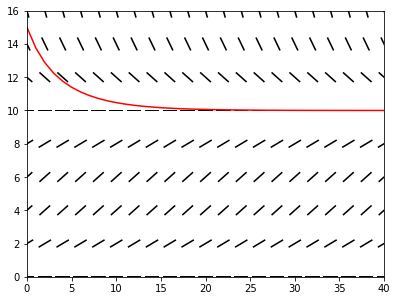

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
richtungsfeld(Rational(2, 100) * y * (10 - y), xb=(0, 40), yb=(0, 16), schritt=2)
g = 10 / (1 - Rational(1, 3) * exp(-Rational(1, 5) * x))
xs = list(range(41))
plt.plot(xs, [float(g.subs(x, w)) for w in xs], 'r')
plt.show()
```

</details>

## 4. Schwingungen

#### y'' = −ω² · y

Bei einer Feder ist die Beschleunigung der Auslenkung entgegengesetzt und proportional zu ihr: y'' = −ω²·y (**harmonische Schwingung**).
Die Lösungen sind y = C1·sin(ωx) + C2·cos(ωx) mit der Periode 2π/ω. Für eine eindeutige Lösung braucht man **zwei** Anfangswerte: Auslenkung y(0) und
Geschwindigkeit y'(0). In sympy: `ics={Y(0): 1, Y(x).diff(x).subs(x, 0): 0}`.

Mit Reibung kommt ein Term mit y' dazu (**gedämpfte Schwingung**), z. B. y'' + 0,5·y' + 4y = 0; die Amplitude nimmt dann exponentiell ab.

In [ ]:
sw = Eq(Y(x).diff(x, 2), -4 * Y(x))
display(dsolve(sw, Y(x)))
l = dsolve(sw, Y(x), ics={Y(0): 1, Y(x).diff(x).subs(x, 0): 0})
display(l)
d = dsolve(Eq(Y(x).diff(x, 2) + Rational(1, 2) * Y(x).diff(x) + 4 * Y(x), 0), Y(x), ics={Y(0): 1, Y(x).diff(x).subs(x, 0): 0})
plot(l.rhs, d.rhs, (x, 0, 10), legend=True);

#### Aufgabe 4.1

Löse y'' = −9y allgemein und gib die Periode der Lösungen aus.

**Erwartete Ausgabe:**

$\displaystyle y{\left(x \right)} = C_{1} \sin{\left(3 x \right)} + C_{2} \cos{\left(3 x \right)}$

$\displaystyle \frac{2 \pi}{3}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(dsolve(Eq(Y(x).diff(x, 2), -9 * Y(x)), Y(x)))
2 * pi / 3
```

</details>

#### Aufgabe 4.2

Löse y'' = −9y mit y(0) = 0 und y'(0) = 6.

**Erwartete Ausgabe:**

$\displaystyle y{\left(x \right)} = 2 \sin{\left(3 x \right)}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
dsolve(Eq(Y(x).diff(x, 2), -9 * Y(x)), Y(x), ics={Y(0): 0, Y(x).diff(x).subs(x, 0): 6})
```

</details>

#### Aufgabe 4.3

Prüfe mit `checkodesol`, dass y = 3·cos(2x) + sin(2x) die Gleichung y'' + 4y = 0 löst.

**Erwartete Ausgabe:**

```
(True, 0)
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
checkodesol(Eq(Y(x).diff(x, 2) + 4 * Y(x), 0), Eq(Y(x), 3 * cos(2*x) + sin(2*x)))
```

</details>

#### Aufgabe 4.4

Löse die gedämpfte Schwingung y'' + 2y' + 5y = 0 mit y(0) = 1, y'(0) = −1.

**Erwartete Ausgabe:**

$\displaystyle y{\left(x \right)} = e^{- x} \cos{\left(2 x \right)}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
dsolve(Eq(Y(x).diff(x, 2) + 2 * Y(x).diff(x) + 5 * Y(x), 0), Y(x), ics={Y(0): 1, Y(x).diff(x).subs(x, 0): -1})
```

</details>

#### Aufgabe 4.5

**Federpendel:** Eine Masse m = 0,5 kg hängt an einer Feder mit D = 8 N/m. Es gilt m·y'' = −D·y. Wie groß ist ω (ω² = D/m), und wie lange dauert eine Schwingung (4 Ziffern)?

*Schreibe Brüche und Kommazahlen mit `Rational`, z. B. `Rational(1, 6)` oder `Rational('0.5')`.*

**Erwartete Ausgabe:**

$\displaystyle 4$

$\displaystyle 1.571$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
w = sqrt(Rational(8) / Rational(1, 2))
display(w)
N(2 * pi / w, 4)
```

</details>

#### Aufgabe 4.6

Zeichne die Lösung von y'' + 0,3·y' + y = 0 mit y(0) = 2, y'(0) = 0 für 0 ≤ x ≤ 30 (0,3 als `Rational`).

**Erwartete Ausgabe:**



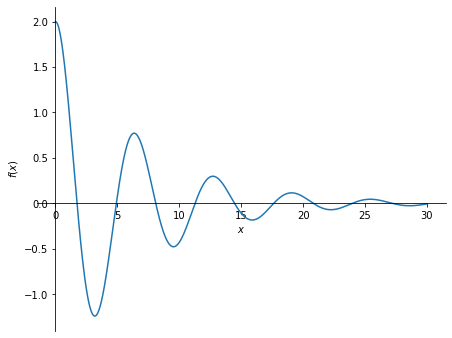

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
l = dsolve(Eq(Y(x).diff(x, 2) + Rational(3, 10) * Y(x).diff(x) + Y(x), 0), Y(x), ics={Y(0): 2, Y(x).diff(x).subs(x, 0): 0})
plot(l.rhs, (x, 0, 30));
```

</details>

## 5. Das explizite Euler-Verfahren

#### Schritt für Schritt entlang der Tangente

Wenn man keine Formel für die Lösung findet, rechnet man **numerisch**. Beim **expliziten Euler-Verfahren** geht man vom Anfangspunkt (x₀ | y₀) mit der
Schrittweite h jeweils ein Stück entlang der Steigung, die die DGL im **aktuellen** Punkt vorgibt:

xₖ₊₁ = xₖ + h,  yₖ₊₁ = yₖ + h · f(xₖ, yₖ)

Beispiel y' = y, y(0) = 1 (genaue Lösung eˣ), h = 0,1. Gerechnet wird mit Kommazahlen; `round(w, 4)` rundet auf 4 Nachkommastellen.

In [ ]:
f = lambdify((x, y), y)
h = 0.1
xs, ys = [0.0], [1.0]
for i in range(10):
    ys.append(ys[-1] + h * f(xs[-1], ys[-1]))
    xs.append(xs[-1] + h)
display([round(w, 4) for w in ys])
display(round(ys[-1], 4), N(E, 5))
plt.plot(xs, ys, 'o-', label='Euler')
plt.plot(xs, [float(exp(w)) for w in xs], label='e^x')
plt.legend()
plt.show()

#### Aufgabe 5.1

Schreibe eine Funktion `euler(steigung, x0, y0, h, schritte)`, die die Listen xs und ys zurückgibt. Teste mit y' = y, y(0) = 1, h = 0,1, 10 Schritte
und gib den letzten y-Wert auf 4 Stellen gerundet aus.

**Erwartete Ausgabe:**

$\displaystyle 2.5937$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def euler(steigung, x0, y0, h, schritte):
    f = lambdify((x, y), steigung)
    xs, ys = [x0], [y0]
    for i in range(schritte):
        ys.append(ys[-1] + h * f(xs[-1], ys[-1]))
        xs.append(xs[-1] + h)
    return xs, ys

xs, ys = euler(y, 0.0, 1.0, 0.1, 10)
round(ys[-1], 4)
```

</details>

#### Aufgabe 5.2

Berechne mit dem expliziten Euler-Verfahren y(1) für y' = y, y(0) = 1 mit h = 0,1, 0,01 und 0,001 (auf 5 Stellen gerundet).

**Erwartete Ausgabe:**

$\displaystyle \left[ 2.59374, \  2.70481, \  2.71692\right]$

In [ ]:
def euler(steigung, x0, y0, h, schritte):
    f = lambdify((x, y), steigung)
    xs, ys = [x0], [y0]
    for i in range(schritte):
        ys.append(ys[-1] + h * f(xs[-1], ys[-1]))
        xs.append(xs[-1] + h)
    return xs, ys
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def euler(steigung, x0, y0, h, schritte):
    f = lambdify((x, y), steigung)
    xs, ys = [x0], [y0]
    for i in range(schritte):
        ys.append(ys[-1] + h * f(xs[-1], ys[-1]))
        xs.append(xs[-1] + h)
    return xs, ys

[round(euler(y, 0.0, 1.0, h, round(1 / h))[1][-1], 5) for h in [0.1, 0.01, 0.001]]
```

</details>

#### Aufgabe 5.3

Löse y' = x − y, y(0) = 1 mit Euler (h = 0,2, 10 Schritte) und gib die y-Werte auf 3 Stellen gerundet aus. Vergleiche y(2) mit der genauen Lösung (4 Ziffern).

**Erwartete Ausgabe:**

$\displaystyle \left[ 1.0, \  0.8, \  0.68, \  0.624, \  0.619, \  0.655, \  0.724, \  0.819, \  0.936, \  1.068, \  1.215\right]$

$\displaystyle 1.271$

In [ ]:
def euler(steigung, x0, y0, h, schritte):
    f = lambdify((x, y), steigung)
    xs, ys = [x0], [y0]
    for i in range(schritte):
        ys.append(ys[-1] + h * f(xs[-1], ys[-1]))
        xs.append(xs[-1] + h)
    return xs, ys
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def euler(steigung, x0, y0, h, schritte):
    f = lambdify((x, y), steigung)
    xs, ys = [x0], [y0]
    for i in range(schritte):
        ys.append(ys[-1] + h * f(xs[-1], ys[-1]))
        xs.append(xs[-1] + h)
    return xs, ys

xs, ys = euler(x - y, 0.0, 1.0, 0.2, 10)
display([round(w, 3) for w in ys])
loes = dsolve(dgl(x - y), Y(x), ics={Y(0): 1})
N(loes.rhs.subs(x, 2), 4)
```

</details>

#### Aufgabe 5.4

Logistisches Wachstum mit Euler: y' = 0,02·y·(10 − y), y(0) = 1, h = 1, 40 Schritte. Gib y nach 10, 20, 30, 40 Schritten auf 3 Stellen gerundet aus.

**Erwartete Ausgabe:**

$\displaystyle \left[ 4.262, \  8.543, \  9.814, \  9.98\right]$

In [ ]:
def euler(steigung, x0, y0, h, schritte):
    f = lambdify((x, y), steigung)
    xs, ys = [x0], [y0]
    for i in range(schritte):
        ys.append(ys[-1] + h * f(xs[-1], ys[-1]))
        xs.append(xs[-1] + h)
    return xs, ys
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def euler(steigung, x0, y0, h, schritte):
    f = lambdify((x, y), steigung)
    xs, ys = [x0], [y0]
    for i in range(schritte):
        ys.append(ys[-1] + h * f(xs[-1], ys[-1]))
        xs.append(xs[-1] + h)
    return xs, ys

xs, ys = euler(0.02 * y * (10 - y), 0.0, 1.0, 1.0, 40)
[round(ys[i], 3) for i in [10, 20, 30, 40]]
```

</details>

#### Aufgabe 5.5

Zeichne die Euler-Näherung (h = 1) und die genaue Lösung 10/(1 + 9·e^(−0,2x)) der vorigen Aufgabe in ein Diagramm (mit Legende).

**Erwartete Ausgabe:**



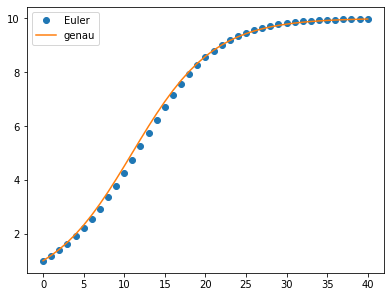

In [ ]:
def euler(steigung, x0, y0, h, schritte):
    f = lambdify((x, y), steigung)
    xs, ys = [x0], [y0]
    for i in range(schritte):
        ys.append(ys[-1] + h * f(xs[-1], ys[-1]))
        xs.append(xs[-1] + h)
    return xs, ys
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def euler(steigung, x0, y0, h, schritte):
    f = lambdify((x, y), steigung)
    xs, ys = [x0], [y0]
    for i in range(schritte):
        ys.append(ys[-1] + h * f(xs[-1], ys[-1]))
        xs.append(xs[-1] + h)
    return xs, ys

xs, ys = euler(0.02 * y * (10 - y), 0.0, 1.0, 1.0, 40)
plt.plot(xs, ys, 'o', label='Euler')
plt.plot(xs, [float(10 / (1 + 9 * exp(-w / 5))) for w in xs], label='genau')
plt.legend()
plt.show()
```

</details>

#### Schwingungen mit Euler

Eine DGL 2. Ordnung wie y'' = −ω²·y schreibt man als zwei Gleichungen 1. Ordnung mit der Geschwindigkeit v = y':
y' = v, v' = −ω²·y. Euler rechnet beide gleichzeitig weiter (mit den **alten** Werten):

yₖ₊₁ = yₖ + h·vₖ,  vₖ₊₁ = vₖ − h·ω²·yₖ

Für ω = 1 ist die genaue Lösung y = cos x, v = −sin x, also immer y² + v² = 1 (die Energie bleibt gleich). An y² + v² sieht man den Fehler des Verfahrens.

In [ ]:
h, om = 0.1, 1.0
ys, vs = [1.0], [0.0]
for i in range(100):
    ys.append(ys[-1] + h * vs[-1])
    vs.append(vs[-1] - h * om**2 * ys[-2])
ts = [i * h for i in range(101)]
plt.plot(ts, ys, label='Euler')
plt.plot(ts, [float(cos(w)) for w in ts], label='cos')
plt.legend()
plt.show()
round(ys[-1]**2 + vs[-1]**2, 3)

#### Aufgabe 5.6

Rechne die Schwingung y'' = −y, y(0) = 1, y'(0) = 0 mit Euler und h = 0,05 für 200 Schritte (bis x = 10). Gib y² + v² am Ende auf 3 Stellen gerundet aus.
(Genau wäre es 1; das explizite Verfahren lässt die Schwingung immer größer werden.)

**Erwartete Ausgabe:**

$\displaystyle 1.648$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
h = 0.05
ys, vs = [1.0], [0.0]
for i in range(200):
    ys.append(ys[-1] + h * vs[-1])
    vs.append(vs[-1] - h * ys[-2])
round(ys[-1]**2 + vs[-1]**2, 3)
```

</details>

## 6. Das implizite Euler-Verfahren

#### Die Steigung am neuen Punkt

Beim **impliziten Euler-Verfahren** nimmt man die Steigung am **neuen** Punkt:

yₖ₊₁ = yₖ + h · f(xₖ₊₁, yₖ₊₁)

Das unbekannte yₖ₊₁ steht auf beiden Seiten, man muss in jedem Schritt eine **Gleichung lösen**. Dafür ist ein CAS praktisch: `nsolve(gleichung, z, start)`
löst sie numerisch, als Startwert nimmt man yₖ.

Für y' = k·y kann man von Hand auflösen: yₖ₊₁ = yₖ + h·k·yₖ₊₁ ⟹ yₖ₊₁ = yₖ / (1 − h·k).

In [ ]:
z = symbols('z')
f = y
h = 0.1
ys = [1.0]
for i in range(10):
    xneu = (i + 1) * h
    ys.append(float(nsolve(z - ys[-1] - h * f.subs({x: xneu, y: z}), z, ys[-1])))
display([round(w, 4) for w in ys])
display(round(1 / (1 - 0.1)**10, 4), N(E, 5))

#### Aufgabe 6.1

Schreibe eine Funktion `euler_implizit(steigung, x0, y0, h, schritte)` (wie im Beispiel mit `nsolve`). Teste mit y' = y, y(0) = 1, h = 0,1, 10 Schritte
(letzter Wert auf 4 Stellen gerundet).

**Erwartete Ausgabe:**

$\displaystyle 2.868$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def euler_implizit(steigung, x0, y0, h, schritte):
    z = symbols('z')
    xs, ys = [x0], [y0]
    for i in range(schritte):
        xs.append(xs[-1] + h)
        ys.append(float(nsolve(z - ys[-1] - h * steigung.subs({x: xs[-1], y: z}), z, ys[-1])))
    return xs, ys

xs, ys = euler_implizit(y, 0.0, 1.0, 0.1, 10)
round(ys[-1], 4)
```

</details>

#### Aufgabe 6.2

Vergleiche für y' = y, y(0) = 1 die Werte y(1) des expliziten und des impliziten Verfahrens mit h = 0,1 mit e (alle auf 4 Stellen). Das explizite Verfahren liegt
darunter, das implizite darüber.

**Erwartete Ausgabe:**

$\displaystyle \left[ 2.5937, \  2.868, \  2.7183\right]$

In [ ]:
def euler(steigung, x0, y0, h, schritte):
    f = lambdify((x, y), steigung)
    xs, ys = [x0], [y0]
    for i in range(schritte):
        ys.append(ys[-1] + h * f(xs[-1], ys[-1]))
        xs.append(xs[-1] + h)
    return xs, ys
def euler_implizit(steigung, x0, y0, h, schritte):
    z = symbols('z')
    xs, ys = [x0], [y0]
    for i in range(schritte):
        xs.append(xs[-1] + h)
        ys.append(float(nsolve(z - ys[-1] - h * steigung.subs({x: xs[-1], y: z}), z, ys[-1])))
    return xs, ys
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def euler(steigung, x0, y0, h, schritte):
    f = lambdify((x, y), steigung)
    xs, ys = [x0], [y0]
    for i in range(schritte):
        ys.append(ys[-1] + h * f(xs[-1], ys[-1]))
        xs.append(xs[-1] + h)
    return xs, ys
def euler_implizit(steigung, x0, y0, h, schritte):
    z = symbols('z')
    xs, ys = [x0], [y0]
    for i in range(schritte):
        xs.append(xs[-1] + h)
        ys.append(float(nsolve(z - ys[-1] - h * steigung.subs({x: xs[-1], y: z}), z, ys[-1])))
    return xs, ys

[round(euler(y, 0.0, 1.0, 0.1, 10)[1][-1], 4), round(euler_implizit(y, 0.0, 1.0, 0.1, 10)[1][-1], 4), round(float(E), 4)]
```

</details>

#### Aufgabe 6.3

Löse y' = x − y, y(0) = 1 mit dem impliziten Verfahren (h = 0,2, 10 Schritte) und gib y(2) auf 4 Stellen gerundet aus.

**Erwartete Ausgabe:**

$\displaystyle 1.323$

In [ ]:
def euler_implizit(steigung, x0, y0, h, schritte):
    z = symbols('z')
    xs, ys = [x0], [y0]
    for i in range(schritte):
        xs.append(xs[-1] + h)
        ys.append(float(nsolve(z - ys[-1] - h * steigung.subs({x: xs[-1], y: z}), z, ys[-1])))
    return xs, ys
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def euler_implizit(steigung, x0, y0, h, schritte):
    z = symbols('z')
    xs, ys = [x0], [y0]
    for i in range(schritte):
        xs.append(xs[-1] + h)
        ys.append(float(nsolve(z - ys[-1] - h * steigung.subs({x: xs[-1], y: z}), z, ys[-1])))
    return xs, ys

round(euler_implizit(x - y, 0.0, 1.0, 0.2, 10)[1][-1], 4)
```

</details>

#### Aufgabe 6.4

Logistisches Wachstum implizit: y' = 0,02·y·(10 − y), y(0) = 1, h = 1. Gib y nach 10, 20, 30, 40 Schritten auf 3 Stellen gerundet aus.

**Erwartete Ausgabe:**

$\displaystyle \left[ 4.76, \  8.617, \  9.752, \  9.959\right]$

In [ ]:
def euler_implizit(steigung, x0, y0, h, schritte):
    z = symbols('z')
    xs, ys = [x0], [y0]
    for i in range(schritte):
        xs.append(xs[-1] + h)
        ys.append(float(nsolve(z - ys[-1] - h * steigung.subs({x: xs[-1], y: z}), z, ys[-1])))
    return xs, ys
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def euler_implizit(steigung, x0, y0, h, schritte):
    z = symbols('z')
    xs, ys = [x0], [y0]
    for i in range(schritte):
        xs.append(xs[-1] + h)
        ys.append(float(nsolve(z - ys[-1] - h * steigung.subs({x: xs[-1], y: z}), z, ys[-1])))
    return xs, ys

xs, ys = euler_implizit(Rational(2, 100) * y * (10 - y), 0.0, 1.0, 1.0, 40)
[round(ys[i], 3) for i in [10, 20, 30, 40]]
```

</details>

#### Aufgabe 6.5

Implizit für die Schwingung: y' = v, v' = −y. Mit den neuen Werten gilt yₖ₊₁ = yₖ + h·vₖ₊₁, vₖ₊₁ = vₖ − h·yₖ₊₁. Löse dieses lineare System für einen Schritt allgemein
nach yₖ₊₁ und vₖ₊₁.

**Erwartete Ausgabe:**

$\displaystyle \left\{ v_{k+1} : \frac{- h y_{k} + v_{k}}{h^{2} + 1}, \  y_{k+1} : \frac{h v_{k} + y_{k}}{h^{2} + 1}\right\}$

In [ ]:
yk, vk, h0, yn, vn = symbols('y_k v_k h y_{k+1} v_{k+1}')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
yk, vk, h0, yn, vn = symbols('y_k v_k h y_{k+1} v_{k+1}')
solve([Eq(yn, yk + h0 * vn), Eq(vn, vk - h0 * yn)], [yn, vn])
```

</details>

#### Aufgabe 6.6

Rechne damit die Schwingung y'' = −y, y(0) = 1, y'(0) = 0 implizit mit h = 0,05 für 200 Schritte und gib y² + v² am Ende
auf 3 Stellen gerundet aus. (Beim impliziten Verfahren wird die Schwingung immer kleiner.)

**Erwartete Ausgabe:**

$\displaystyle 0.607$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
h = 0.05
ys, vs = [1.0], [0.0]
for i in range(200):
    yk, vk = ys[-1], vs[-1]
    ys.append((yk + h * vk) / (1 + h**2))
    vs.append((vk - h * yk) / (1 + h**2))
round(ys[-1]**2 + vs[-1]**2, 3)
```

</details>

## 7. Die Güte der Näherung

#### Schrittweite und Verfahren

Der Fehler des Euler-Verfahrens hängt von der **Schrittweite** ab: Halbiert man h, halbiert sich der Fehler an einer festen Stelle ungefähr
(das Verfahren hat die **Ordnung 1**). Doppelte Genauigkeit kostet also doppelt so viele Schritte.

Bei manchen Gleichungen ist das explizite Verfahren bei zu großem h sogar **instabil**: Für y' = −10·y (genaue Lösung fällt schnell auf 0) springen
die Euler-Werte bei h = 0,25 hin und her und wachsen. Das implizite Verfahren bleibt stabil.

In [ ]:
def euler(steigung, x0, y0, h, schritte):
    f = lambdify((x, y), steigung)
    xs, ys = [x0], [y0]
    for i in range(schritte):
        ys.append(ys[-1] + h * f(xs[-1], ys[-1]))
        xs.append(xs[-1] + h)
    return xs, ys

fehler = [(h, round(float(E) - euler(y, 0.0, 1.0, h, round(1 / h))[1][-1], 5)) for h in [0.1, 0.05, 0.025, 0.0125]]
display(fehler)
display([round(w, 2) for w in euler(-10 * y, 0.0, 1.0, 0.25, 8)[1]])
[round(1 / (1 + 10 * 0.25)**i, 4) for i in range(9)]

#### Aufgabe 7.1

Berechne für y' = y, y(0) = 1 die Fehler e − y(1) des expliziten Verfahrens für h = 0,1, 0,05, 0,025 und die Quotienten aufeinanderfolgender Fehler (auf 3 Stellen).

**Erwartete Ausgabe:**

$\displaystyle \left[ 1.916, \  1.956\right]$

In [ ]:
def euler(steigung, x0, y0, h, schritte):
    f = lambdify((x, y), steigung)
    xs, ys = [x0], [y0]
    for i in range(schritte):
        ys.append(ys[-1] + h * f(xs[-1], ys[-1]))
        xs.append(xs[-1] + h)
    return xs, ys
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def euler(steigung, x0, y0, h, schritte):
    f = lambdify((x, y), steigung)
    xs, ys = [x0], [y0]
    for i in range(schritte):
        ys.append(ys[-1] + h * f(xs[-1], ys[-1]))
        xs.append(xs[-1] + h)
    return xs, ys

f = [float(E) - euler(y, 0.0, 1.0, h, round(1 / h))[1][-1] for h in [0.1, 0.05, 0.025]]
[round(f[0] / f[1], 3), round(f[1] / f[2], 3)]
```

</details>

#### Aufgabe 7.2

Wie viele Schritte braucht das explizite Verfahren für y' = y, y(0) = 1, damit y(1) auf 0,001 genau ist? Verdopple die Schrittzahl ab 10, bis |e − y(1)| < 0,001.

**Erwartete Ausgabe:**

$\displaystyle 2560$

In [ ]:
def euler(steigung, x0, y0, h, schritte):
    f = lambdify((x, y), steigung)
    xs, ys = [x0], [y0]
    for i in range(schritte):
        ys.append(ys[-1] + h * f(xs[-1], ys[-1]))
        xs.append(xs[-1] + h)
    return xs, ys
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def euler(steigung, x0, y0, h, schritte):
    f = lambdify((x, y), steigung)
    xs, ys = [x0], [y0]
    for i in range(schritte):
        ys.append(ys[-1] + h * f(xs[-1], ys[-1]))
        xs.append(xs[-1] + h)
    return xs, ys

m = 10
while abs(float(E) - euler(y, 0.0, 1.0, 1 / m, m)[1][-1]) >= 0.001:
    m *= 2
m
```

</details>

#### Aufgabe 7.3

Untersuche die Stabilität für y' = −10·y, y(0) = 1: Gib die ersten 6 Werte des expliziten Verfahrens für h = 0,05 und h = 0,25 aus (auf 3 Stellen).

**Erwartete Ausgabe:**

$\displaystyle \left[ 1.0, \  0.5, \  0.25, \  0.125, \  0.062, \  0.031\right]$

$\displaystyle \left[ 1.0, \  -1.5, \  2.25, \  -3.375, \  5.062, \  -7.594\right]$

In [ ]:
def euler(steigung, x0, y0, h, schritte):
    f = lambdify((x, y), steigung)
    xs, ys = [x0], [y0]
    for i in range(schritte):
        ys.append(ys[-1] + h * f(xs[-1], ys[-1]))
        xs.append(xs[-1] + h)
    return xs, ys
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def euler(steigung, x0, y0, h, schritte):
    f = lambdify((x, y), steigung)
    xs, ys = [x0], [y0]
    for i in range(schritte):
        ys.append(ys[-1] + h * f(xs[-1], ys[-1]))
        xs.append(xs[-1] + h)
    return xs, ys

display([round(w, 3) for w in euler(-10 * y, 0.0, 1.0, 0.05, 5)[1]])
[round(w, 3) for w in euler(-10 * y, 0.0, 1.0, 0.25, 5)[1]]
```

</details>

#### Aufgabe 7.4

Das **Verfahren von Heun** (verbessertes Euler-Verfahren) nimmt den Mittelwert der Steigungen am alten und am vorläufigen neuen Punkt:
p = yₖ + h·f(xₖ, yₖ), yₖ₊₁ = yₖ + h/2·(f(xₖ, yₖ) + f(xₖ₊₁, p)). Berechne damit y(1) für y' = y, y(0) = 1, h = 0,1 und den Fehler (auf 5 Stellen). **(Zusatz)**

**Erwartete Ausgabe:**

$\displaystyle \left( 2.71408, \  0.0042\right)$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = lambdify((x, y), y)
h = 0.1
xk, yk = 0.0, 1.0
for i in range(10):
    p = yk + h * f(xk, yk)
    yk = yk + h / 2 * (f(xk, yk) + f(xk + h, p))
    xk = xk + h
(round(yk, 5), round(float(E) - yk, 5))
```

</details>